# FraudShield: model comparison figures for the report

This notebook only **reads** the files written by `train.ipynb` (it trains nothing) and turns them into report-ready figures.

| Input (in `models/reports/` unless noted) | Used for |
|---|---|
| `model_comparison_paysim.csv`, `model_comparison_sparkov.csv` | Figures 1-5 and 9, results table |
| `../model_comparison.csv` | Consistency check against the per-dataset files |
| `feature_importance_<dataset>.csv` | Figure 7 |
| `fairness_audit_sparkov_gender.csv` | Figure 8 |
| `../fraudshield_<dataset>_metadata.json` | Figure 6 (confusion matrices), deployed-model markers |
| `pr_curves_<dataset>.png` | Figure 10 |

Every figure is saved as a 300 dpi PNG in `models/reports/figures/`.

| Fig | Shows |
|---|---|
| 1 | Precision, recall and F1 of every model |
| 2 | Validation vs test PR-AUC (model selection and generalisation) |
| 3 | Effect of threshold tuning (F1 at 0.5 vs tuned threshold) |
| 4 | Precision-recall trade-off per model |
| 5 | Training cost vs accuracy |
| 6 | Confusion matrices of the deployed models |
| 7 | What drives each model's decisions |
| 8 | Fairness audit by gender |
| 9 | Heatmap of all metrics |
| 10 | Precision-recall curves from training |

In [1]:
import json, os
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter, PercentFormatter

try:
    from IPython.display import display
except ImportError:          # plain-python fallback
    display = print

# models/ lives at the project root (same rule as train.ipynb)
ROOT = Path.cwd()
if not (ROOT / "models").exists() and (ROOT.parent / "models").exists():
    ROOT = ROOT.parent
MODELS_DIR = Path(os.environ.get("FS_MODELS_DIR", ROOT / "models"))
REPORTS_DIR = ROOT / "reports"
FIG_DIR = REPORTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "legend.frameon": False,
})

KEYS = ["paysim", "sparkov"]
DATASET_NAMES = {"paysim": "PaySim (mobile money)", "sparkov": "Sparkov (card payments)"}
SHORT = {
    "Logistic Regression (baseline)": "LogReg\n(baseline)", "Random Forest": "RF", "XGBoost": "XGB",
    "Random Forest (tuned)": "RF\n(tuned)", "XGBoost (tuned)": "XGB\n(tuned)",
}
MODEL_COLORS = {
    "Logistic Regression (baseline)": "#9aa3a7", "Random Forest": "#6fa8dc", "XGBoost": "#f6b26b",
    "Random Forest (tuned)": "#2b6cb0", "XGBoost (tuned)": "#d9730d",
}
METRIC_COLORS = ["#4c78a8", "#f58518", "#54a24b"]


def save(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path)
    plt.show()
    print("saved", path)


def bottom_legend(fig, ax):
    """One legend centred under the figure, so it never covers the bars."""
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=len(labels))


def label_points(ax, names, xs, ys, fontsize=8):
    """Label points above (upper half) or below (lower half), alternating left/right
    from the left-most point, so neighbouring labels do not collide."""
    pts = pd.DataFrame({"name": list(names), "x": list(xs), "y": list(ys)})
    pts["up"] = pts["y"] >= pts["y"].median()
    for up, group in pts.groupby("up"):
        for rank, (_, p) in enumerate(group.sort_values("x").iterrows()):
            left = rank % 2 == 0
            ax.annotate(p["name"], (p["x"], p["y"]), xytext=(-7 if left else 7, 9 if up else -14),
                        textcoords="offset points", fontsize=fontsize, ha="right" if left else "left")


def need(path):
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Run train.ipynb first.")
    return path

## Load the training outputs

In [2]:
comp = {k: pd.read_csv(need(REPORTS_DIR / f"model_comparison_{k}.csv")) for k in KEYS}
combined = pd.read_csv(need(MODELS_DIR / "model_comparison.csv"))
importance = {k: pd.read_csv(need(REPORTS_DIR / f"feature_importance_{k}.csv")) for k in KEYS}
fairness = pd.read_csv(need(REPORTS_DIR / "fairness_audit_sparkov_gender.csv"))

meta = {}
for k in KEYS:
    path = MODELS_DIR / f"fraudshield_{k}_metadata.json"
    if path.exists():
        meta[k] = json.loads(path.read_text())

# deployed model = the one recorded by train.ipynb (fallback: best validation PR-AUC, the selection rule)
deployed = {
    k: meta[k]["model"] if k in meta
    else comp[k].sort_values("Val PR-AUC", ascending=False).iloc[0]["Model"]
    for k in KEYS
}
assert len(combined) == sum(len(c) for c in comp.values()), "model_comparison.csv does not match the per-dataset files"

for k in KEYS:
    print(f"{DATASET_NAMES[k]:<26} {len(comp[k])} models compared | deployed: {deployed[k]}")
print("metadata found for:", list(meta) or "none (Figure 6 will be skipped)")


def xlabels(key):
    return [SHORT.get(m, m) + ("\n★ deployed" if m == deployed[key] else "") for m in comp[key]["Model"]]

PaySim (mobile money)      5 models compared | deployed: Random Forest (tuned)
Sparkov (card payments)    5 models compared | deployed: Random Forest (tuned)
metadata found for: ['paysim', 'sparkov']


## Figure 1: Precision, recall and F1 (test set, tuned threshold)

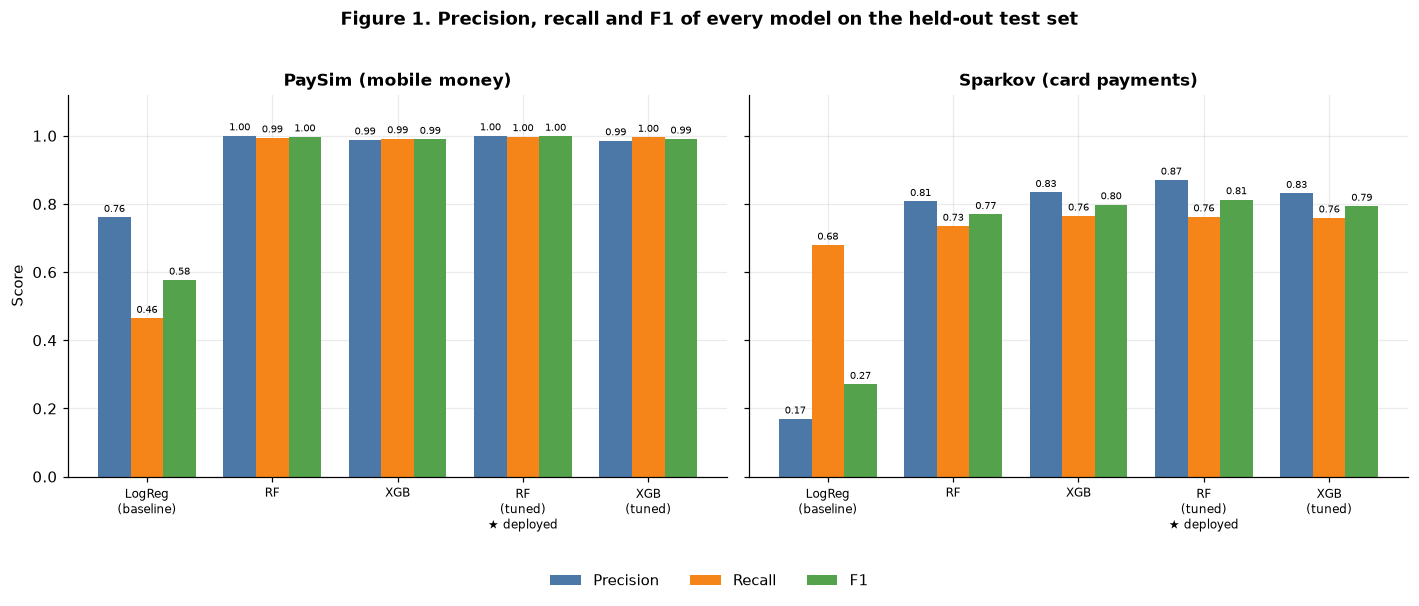

saved c:\Users\muham\Desktop\Stuff\Programs\fraudshield\reports\figures\fig1_precision_recall_f1.png


In [3]:
metrics = [("Precision@thr", "Precision"), ("Recall@thr", "Recall"), ("F1@thr", "F1")]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, key in zip(axes, KEYS):
    d = comp[key]
    x, w = np.arange(len(d)), 0.26
    for i, (col, label) in enumerate(metrics):
        bars = ax.bar(x + (i - 1) * w, d[col], w, label=label, color=METRIC_COLORS[i])
        ax.bar_label(bars, labels=[f"{v:.2f}" for v in d[col]], fontsize=6.5, padding=2)
    ax.set_xticks(x)
    ax.set_xticklabels(xlabels(key), fontsize=8)
    ax.set_ylim(0, 1.12)
    ax.set_title(DATASET_NAMES[key])
axes[0].set_ylabel("Score")
fig.suptitle("Figure 1. Precision, recall and F1 of every model on the held-out test set", y=1.02, fontweight="bold")
fig.tight_layout()
bottom_legend(fig, axes[0])
save(fig, "fig1_precision_recall_f1")

*Figure 1.* Precision, recall and F1 for the baseline and each improved model, evaluated once on the held-out test set at the decision threshold chosen on the validation split. The star marks the model deployed in FraudShield.

## Figure 2: Validation vs test PR-AUC

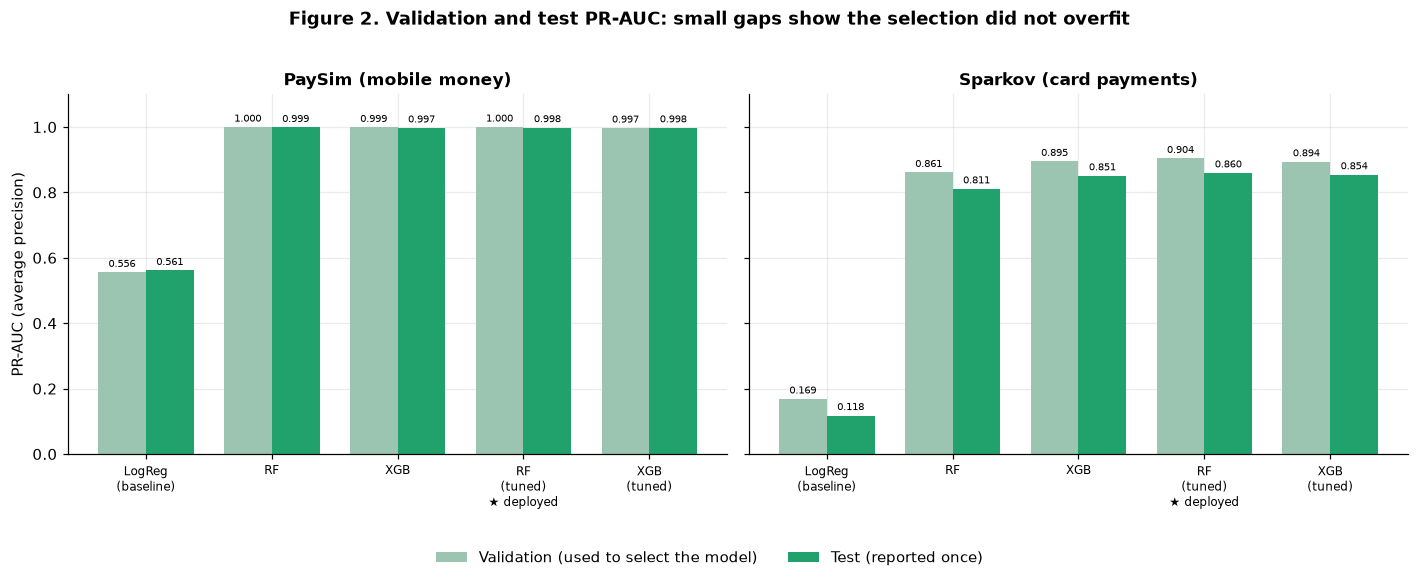

saved c:\Users\muham\Desktop\Stuff\Programs\fraudshield\reports\figures\fig2_val_vs_test_pr_auc.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, key in zip(axes, KEYS):
    d = comp[key]
    x, w = np.arange(len(d)), 0.38
    b1 = ax.bar(x - w / 2, d["Val PR-AUC"], w, label="Validation (used to select the model)", color="#9bc5b0")
    b2 = ax.bar(x + w / 2, d["PR-AUC"], w, label="Test (reported once)", color="#21a16b")
    ax.bar_label(b1, labels=[f"{v:.3f}" for v in d["Val PR-AUC"]], fontsize=6.5, padding=2)
    ax.bar_label(b2, labels=[f"{v:.3f}" for v in d["PR-AUC"]], fontsize=6.5, padding=2)
    ax.set_xticks(x)
    ax.set_xticklabels(xlabels(key), fontsize=8)
    ax.set_ylim(0, 1.1)
    ax.set_title(DATASET_NAMES[key])
axes[0].set_ylabel("PR-AUC (average precision)")
fig.suptitle("Figure 2. Validation and test PR-AUC: small gaps show the selection did not overfit", y=1.02, fontweight="bold")
fig.tight_layout()
bottom_legend(fig, axes[0])
save(fig, "fig2_val_vs_test_pr_auc")

*Figure 2.* PR-AUC is the preferred metric under extreme class imbalance, because ROC-AUC stays close to 1 even for weak detectors. Close validation and test values indicate that choosing the model on validation data did not leak into the test result.

## Figure 3: Effect of threshold tuning

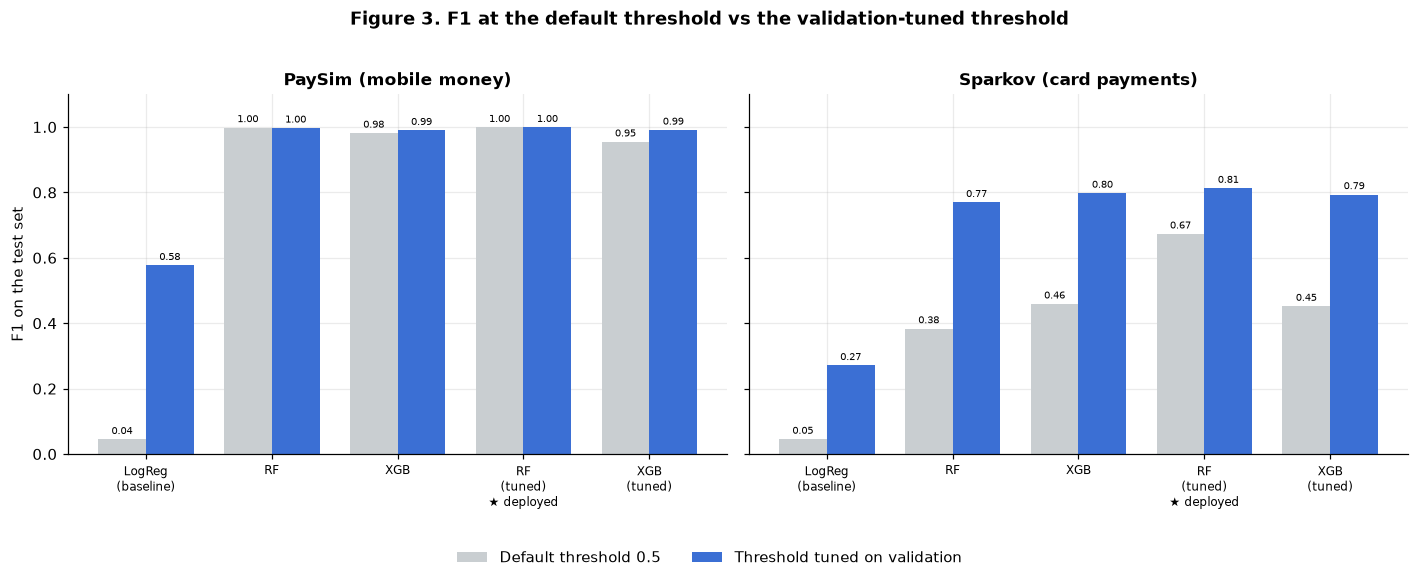

saved c:\Users\muham\Desktop\Stuff\Programs\fraudshield\reports\figures\fig3_threshold_effect.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, key in zip(axes, KEYS):
    d = comp[key]
    x, w = np.arange(len(d)), 0.38
    b1 = ax.bar(x - w / 2, d["F1@0.5"], w, label="Default threshold 0.5", color="#c9ced1")
    b2 = ax.bar(x + w / 2, d["F1@thr"], w, label="Threshold tuned on validation", color="#3b6fd4")
    ax.bar_label(b1, labels=[f"{v:.2f}" for v in d["F1@0.5"]], fontsize=6.5, padding=2)
    ax.bar_label(b2, labels=[f"{v:.2f}" for v in d["F1@thr"]], fontsize=6.5, padding=2)
    ax.set_xticks(x)
    ax.set_xticklabels(xlabels(key), fontsize=8)
    ax.set_ylim(0, 1.1)
    ax.set_title(DATASET_NAMES[key])
axes[0].set_ylabel("F1 on the test set")
fig.suptitle("Figure 3. F1 at the default threshold vs the validation-tuned threshold", y=1.02, fontweight="bold")
fig.tight_layout()
bottom_legend(fig, axes[0])
save(fig, "fig3_threshold_effect")

*Figure 3.* The default 0.5 threshold is a poor choice when fraud is rare and models are trained with class weights. Selecting the threshold on validation data raises F1 most for models that over-flag at 0.5.

## Figure 4: Precision-recall trade-off

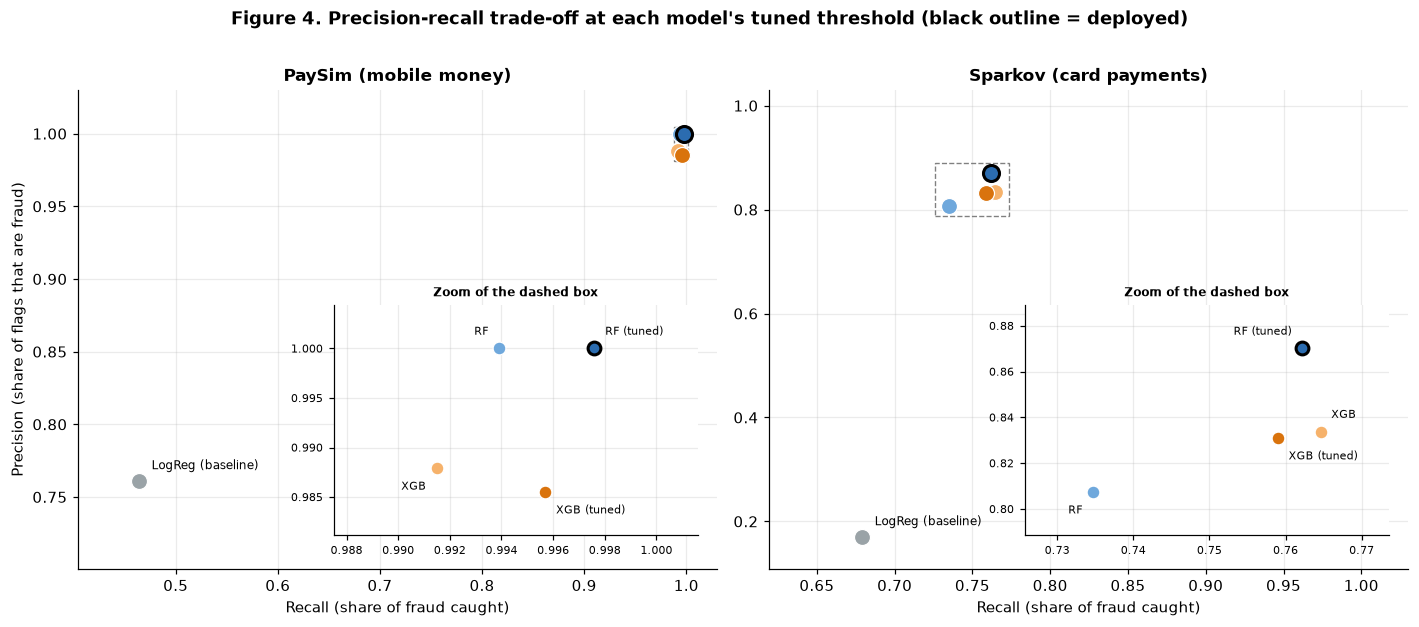

saved c:\Users\muham\Desktop\Stuff\Programs\fraudshield\reports\figures\fig4_precision_recall_tradeoff.png


In [6]:
def draw_models(ax, rows, key, size):
    for _, r in rows.iterrows():
        dep = r["Model"] == deployed[key]
        ax.scatter(r["Recall@thr"], r["Precision@thr"], s=size, color=MODEL_COLORS.get(r["Model"], "#777"),
                   edgecolor="black" if dep else "white", linewidth=2 if dep else 0.8, zorder=3)


fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, key in zip(axes, KEYS):
    d = comp[key].reset_index(drop=True)
    is_base = d["Model"].str.contains("baseline", case=False)
    draw_models(ax, d, key, 110)
    ax.set_xlim(max(0, d["Recall@thr"].min() - 0.06), 1.03)
    ax.set_ylim(max(0, d["Precision@thr"].min() - 0.06), 1.03)
    ax.set_xlabel("Recall (share of fraud caught)")
    ax.set_title(DATASET_NAMES[key])
    for _, r in d[is_base].iterrows():
        ax.annotate(SHORT.get(r["Model"], r["Model"]).replace("\n", " "), (r["Recall@thr"], r["Precision@thr"]),
                    xytext=(8, 8), textcoords="offset points", fontsize=8)

    # zoomed inset: the improved models sit close together, so enlarge their region
    top = d[~is_base]
    if len(top):
        ins = ax.inset_axes([0.40, 0.07, 0.57, 0.48])
        draw_models(ins, top, key, 70)
        px = max(0.15 * (top["Recall@thr"].max() - top["Recall@thr"].min()), 0.002)
        py = max(0.15 * (top["Precision@thr"].max() - top["Precision@thr"].min()), 0.002)
        ins.set_xlim(top["Recall@thr"].min() - 2 * px, top["Recall@thr"].max() + 2 * px)
        ins.set_ylim(top["Precision@thr"].min() - 2 * py, top["Precision@thr"].max() + 2 * py)
        label_points(ins, [SHORT.get(m, m).replace("\n", " ") for m in top["Model"]],
                     top["Recall@thr"], top["Precision@thr"], fontsize=7)
        ins.tick_params(labelsize=7)
        ins.set_title("Zoom of the dashed box", fontsize=8)
        (x0, x1), (y0, y1) = ins.get_xlim(), ins.get_ylim()
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="gray",
                               linestyle="--", linewidth=0.9, zorder=2))
axes[0].set_ylabel("Precision (share of flags that are fraud)")
fig.suptitle("Figure 4. Precision-recall trade-off at each model's tuned threshold (black outline = deployed)", y=1.01, fontweight="bold")
fig.tight_layout()
save(fig, "fig4_precision_recall_tradeoff")

*Figure 4.* Each point is one model. The top-right corner is ideal. The inset enlarges the improved models, which sit close together; the baseline is shown only in the main panel.

## Figure 5: Training cost vs accuracy

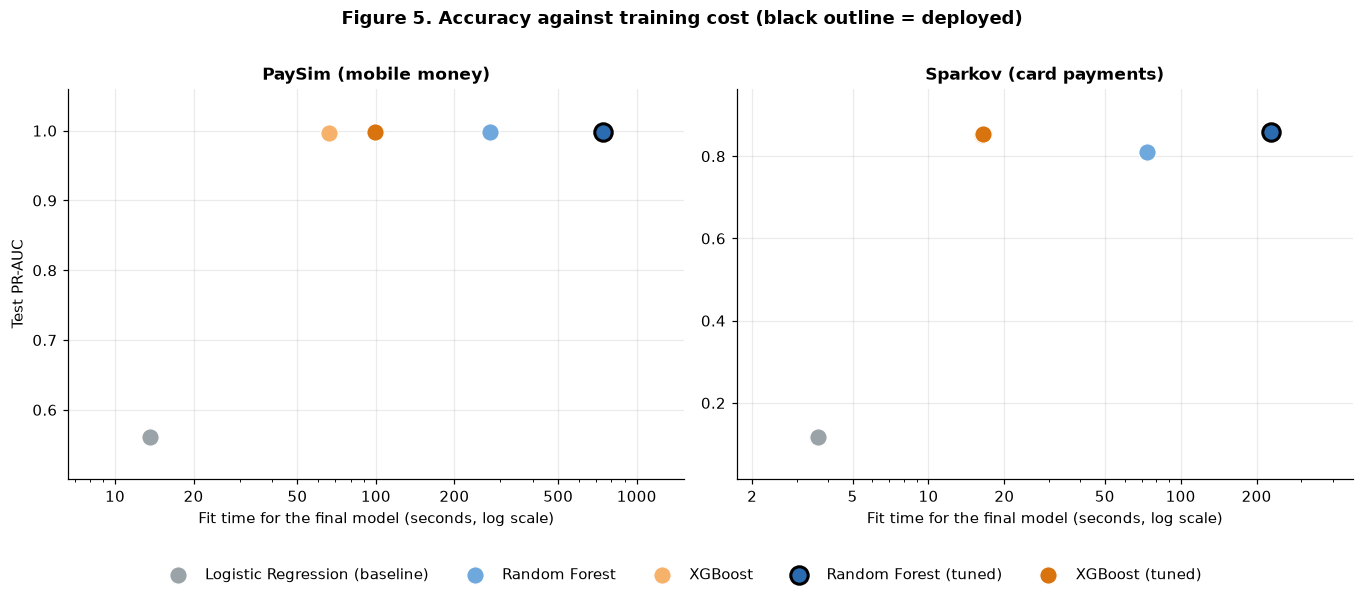

saved c:\Users\muham\Desktop\Stuff\Programs\fraudshield\reports\figures\fig5_cost_vs_accuracy.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for ax, key in zip(axes, KEYS):
    d = comp[key]
    for _, row in d.iterrows():
        ax.scatter(row["Fit seconds"], row["PR-AUC"], s=130, color=MODEL_COLORS.get(row["Model"], "#777"),
                   edgecolor="black" if row["Model"] == deployed[key] else "white",
                   linewidth=2 if row["Model"] == deployed[key] else 0.8, zorder=3, label=row["Model"])
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.margins(x=0.18, y=0.14)
    ax.set_xlabel("Fit time for the final model (seconds, log scale)")
    ax.set_title(DATASET_NAMES[key])
axes[0].set_ylabel("Test PR-AUC")
fig.suptitle("Figure 5. Accuracy against training cost (black outline = deployed)", y=1.01, fontweight="bold")
fig.tight_layout()
bottom_legend(fig, axes[0])
save(fig, "fig5_cost_vs_accuracy")

*Figure 5.* Fit time covers training the final model only, not the hyper-parameter search. It shows how much extra compute each improvement costs for the accuracy it buys. Models with almost identical fit time and PR-AUC plot on top of each other.

## Figure 6: Confusion matrices of the deployed models

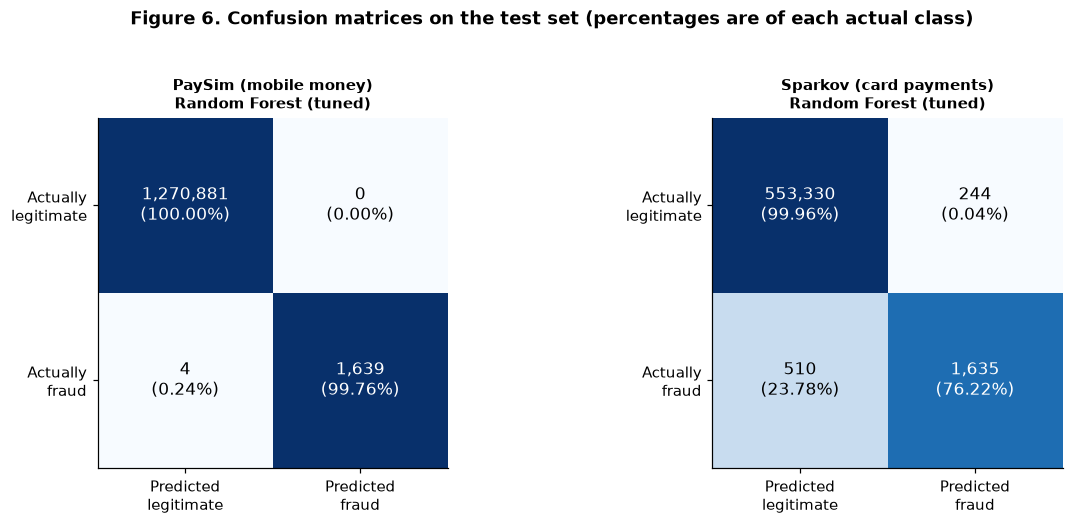

saved c:\Users\muham\Desktop\Stuff\Programs\fraudshield\reports\figures\fig6_confusion_matrices.png


In [8]:
if not meta:
    print("No metadata JSON files found; skipping Figure 6.")
else:
    fig, axes = plt.subplots(1, len(meta), figsize=(5.8 * len(meta), 4.6))
    axes = np.atleast_1d(axes)
    for ax, key in zip(axes, meta):
        cm = meta[key]["confusion_matrix"]
        counts = np.array([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]])
        share = counts / counts.sum(axis=1, keepdims=True)   # colour = share of each true class
        ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{counts[i, j]:,}\n({share[i, j]:.2%})", ha="center", va="center",
                        color="white" if share[i, j] > 0.5 else "black", fontsize=11)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted\nlegitimate", "Predicted\nfraud"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Actually\nlegitimate", "Actually\nfraud"])
        ax.grid(False)
        ax.set_title(f"{DATASET_NAMES[key]}\n{meta[key]['model']}", fontsize=10)
    fig.suptitle("Figure 6. Confusion matrices on the test set (percentages are of each actual class)", y=1.03, fontweight="bold")
    fig.tight_layout()
    save(fig, "fig6_confusion_matrices")

*Figure 6.* Counts and per-class percentages for the deployed models. The bottom-left cell is missed fraud and the top-right cell is false alarms, the two costs the threshold trades off.

## Figure 7: What drives each model's decisions

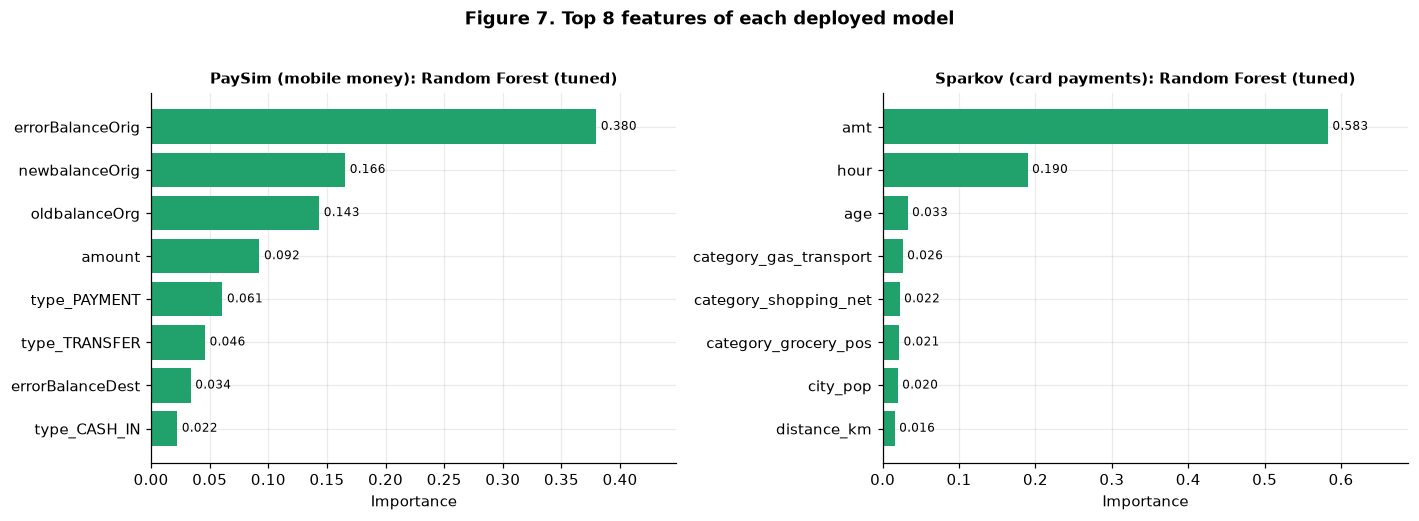

saved c:\Users\muham\Desktop\Stuff\Programs\fraudshield\reports\figures\fig7_feature_importance.png


In [9]:
TOP_N = 8
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, key in zip(axes, KEYS):
    d = importance[key].head(TOP_N).copy()
    d["feature"] = d["feature"].str.replace(r"^(cat|num)__", "", regex=True)
    d = d.iloc[::-1]
    bars = ax.barh(d["feature"], d["importance"], color="#21a16b")
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in d["importance"]], fontsize=8, padding=3)
    ax.set_xlim(0, d["importance"].max() * 1.18)
    ax.set_xlabel("Importance")
    ax.set_title(f"{DATASET_NAMES[key]}: {deployed[key]}", fontsize=10)
fig.suptitle(f"Figure 7. Top {TOP_N} features of each deployed model", y=1.02, fontweight="bold")
fig.tight_layout()
save(fig, "fig7_feature_importance")

*Figure 7.* Feature importance as reported by each deployed model (impurity-based for tree models, absolute coefficients for logistic regression, so values are comparable within a panel only). It shows which inputs the model relies on, not why a single transaction was flagged. One-hot features appear as `column_value`.

## Figure 8: Fairness audit by gender (Sparkov)

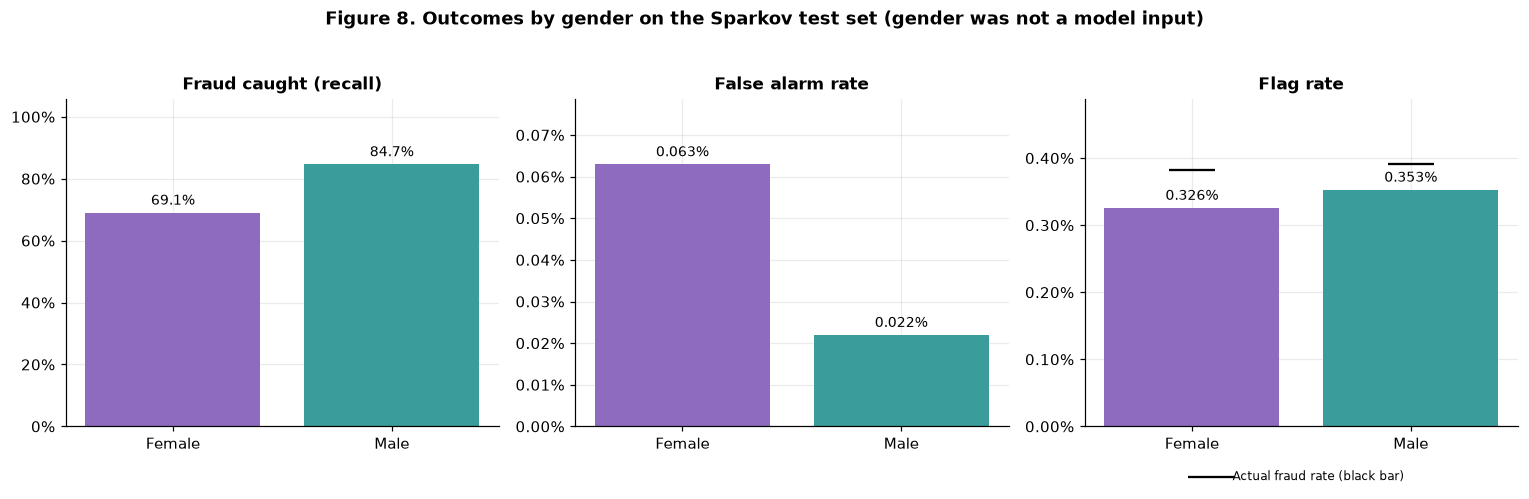

saved c:\Users\muham\Desktop\Stuff\Programs\fraudshield\reports\figures\fig8_fairness_gender.png
Recall: Male 84.7% vs Female 69.1% (gap 15.6 percentage points)
False alarm rate: Female 0.063% vs Male 0.022% (2.9x)


In [10]:
audit = fairness.copy()
audit["group"] = audit["group"].map({"F": "Female", "M": "Male"}).fillna(audit["group"])
colors = ["#8e6bbf", "#3b9c9c", "#c9a227", "#888"][: len(audit)]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
panels = [("recall", "Fraud caught (recall)", "{:.1%}"),
          ("false_positive_rate", "False alarm rate", "{:.3%}"),
          ("flag_rate", "Flag rate", "{:.3%}")]
for ax, (col, title, fmt) in zip(axes, panels):
    bars = ax.bar(audit["group"], audit[col], color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in audit[col]], fontsize=9, padding=3)
    if col == "flag_rate":   # compare with the true fraud rate of each group
        ax.scatter(audit["group"], audit["fraud_rate"], marker="_", s=900, color="black", zorder=4, label="Actual fraud rate (black bar)")
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0 if col == "recall" else 2))
    ax.set_ylim(0, max(audit[col].max(), audit["fraud_rate"].max() if col == "flag_rate" else 0) * 1.25)
    ax.set_title(title)
fig.suptitle("Figure 8. Outcomes by gender on the Sparkov test set (gender was not a model input)", y=1.03, fontweight="bold")
fig.tight_layout()
save(fig, "fig8_fairness_gender")

if len(audit) == 2 and audit["recall"].notna().all():
    hi, lo = audit.sort_values("recall", ascending=False).iloc[0], audit.sort_values("recall", ascending=False).iloc[1]
    print(f"Recall: {hi['group']} {hi['recall']:.1%} vs {lo['group']} {lo['recall']:.1%} "
          f"(gap {100 * (hi['recall'] - lo['recall']):.1f} percentage points)")
    fp_hi, fp_lo = audit.sort_values("false_positive_rate", ascending=False).iloc[[0, 1]].to_dict("records")
    print(f"False alarm rate: {fp_hi['group']} {fp_hi['false_positive_rate']:.3%} vs {fp_lo['group']} "
          f"{fp_lo['false_positive_rate']:.3%} ({fp_hi['false_positive_rate'] / fp_lo['false_positive_rate']:.1f}x)")

*Figure 8.* Gender is excluded from the model and used only for this audit. Any gap between groups therefore comes from other features that correlate with gender. Gaps should be reviewed and mitigated (for example per-group threshold analysis) before real-world use.

## Figure 9: Heatmap of all metrics

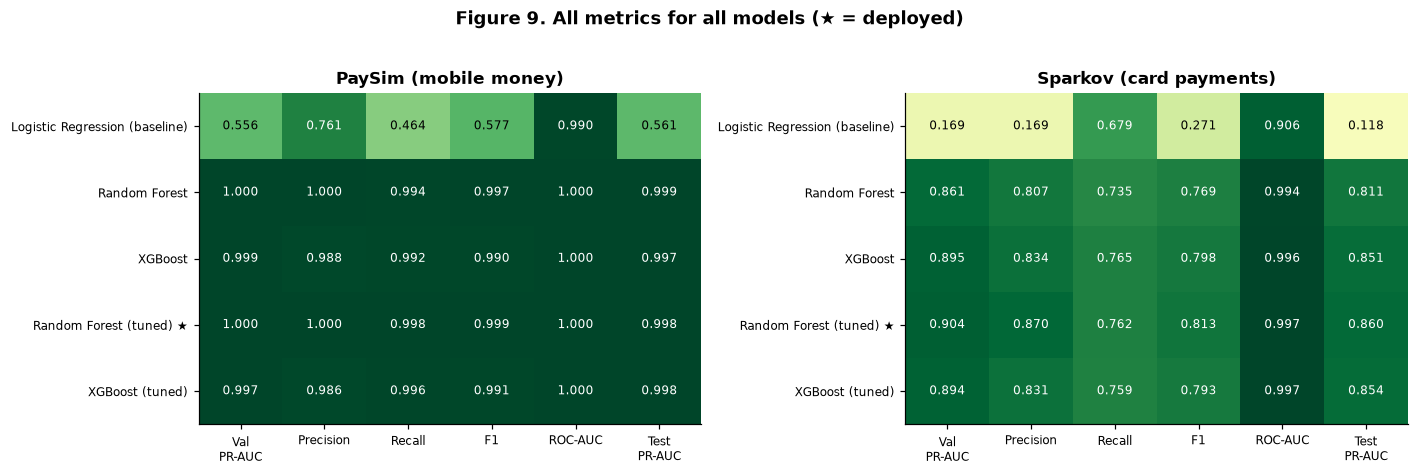

saved c:\Users\muham\Desktop\Stuff\Programs\fraudshield\reports\figures\fig9_metric_heatmap.png


In [11]:
cols = [("Val PR-AUC", "Val\nPR-AUC"), ("Precision@thr", "Precision"), ("Recall@thr", "Recall"),
        ("F1@thr", "F1"), ("ROC-AUC", "ROC-AUC"), ("PR-AUC", "Test\nPR-AUC")]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, key in zip(axes, KEYS):
    d = comp[key]
    values = d[[c for c, _ in cols]].to_numpy(dtype=float)
    ax.imshow(values, cmap="YlGn", vmin=0, vmax=1, aspect="auto")
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            r, g, b, _ = plt.get_cmap("YlGn")(values[i, j])
            ax.text(j, i, f"{values[i, j]:.3f}", ha="center", va="center", fontsize=8,
                    color="white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.5 else "black")
    ax.set_xticks(range(len(cols))); ax.set_xticklabels([label for _, label in cols], fontsize=8)
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels([m + (" ★" if m == deployed[key] else "") for m in d["Model"]], fontsize=8)
    ax.grid(False)
    ax.set_title(DATASET_NAMES[key])
fig.suptitle("Figure 9. All metrics for all models (★ = deployed)", y=1.02, fontweight="bold")
fig.tight_layout()
save(fig, "fig9_metric_heatmap")

*Figure 9.* A single view of every model and metric. Darker green is better. Compare columns to see how metrics disagree: ROC-AUC is high for almost every model, while PR-AUC separates them.

## Figure 10: Precision-recall curves from training

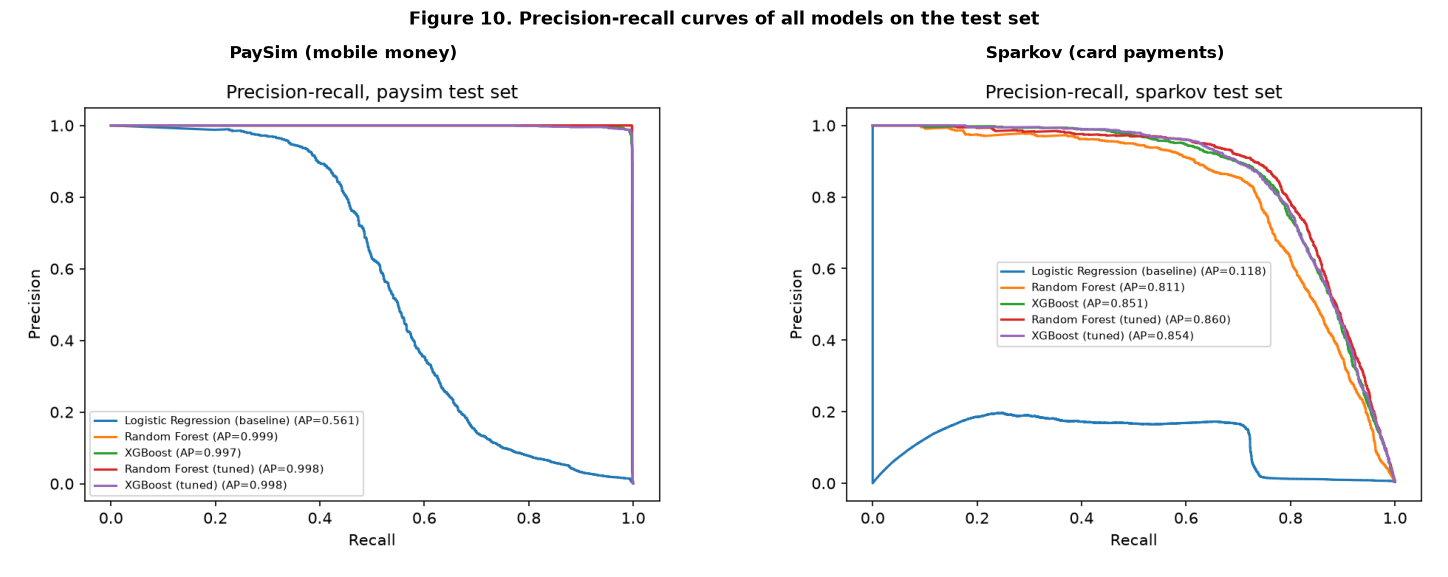

saved c:\Users\muham\Desktop\Stuff\Programs\fraudshield\reports\figures\fig10_pr_curves.png


In [12]:
images = {k: REPORTS_DIR / f"pr_curves_{k}.png" for k in KEYS if (REPORTS_DIR / f"pr_curves_{k}.png").exists()}
if not images:
    print("No pr_curves_*.png files found; skipping Figure 10.")
else:
    fig, axes = plt.subplots(1, len(images), figsize=(7 * len(images), 5.2))
    for ax, (key, path) in zip(np.atleast_1d(axes), images.items()):
        ax.imshow(mpimg.imread(path))
        ax.axis("off")
        ax.set_title(DATASET_NAMES[key])
    fig.suptitle("Figure 10. Precision-recall curves of all models on the test set", y=1.0, fontweight="bold")
    fig.tight_layout()
    save(fig, "fig10_pr_curves")

*Figure 10.* The full curves (rather than the single threshold shown in Figure 4) generated during training. A curve that stays high and to the right separates fraud from legitimate transactions better across all thresholds.

## Results table and key findings

In [13]:
rows = []
for k in KEYS:
    for _, r in comp[k].iterrows():
        rows.append({"Dataset": DATASET_NAMES[k], "Model": r["Model"] + (" ★" if r["Model"] == deployed[k] else ""),
                     "Precision": r["Precision@thr"], "Recall": r["Recall@thr"], "F1": r["F1@thr"],
                     "ROC-AUC": r["ROC-AUC"], "PR-AUC": r["PR-AUC"]})
summary = pd.DataFrame(rows).round(4)
summary.to_csv(FIG_DIR / "results_summary.csv", index=False)
display(summary)

print("\nKey findings (computed from the CSV files):")
for k in KEYS:
    d = comp[k]
    base = d[d["Model"].str.contains("baseline", case=False)].iloc[0] if d["Model"].str.contains("baseline", case=False).any() else d.iloc[0]
    best = d[d["Model"] == deployed[k]].iloc[0]
    print(f"- {DATASET_NAMES[k]}: the deployed {best['Model']} reaches test PR-AUC {best['PR-AUC']:.3f} "
          f"and F1 {best['F1@thr']:.3f}, against {base['PR-AUC']:.3f} and {base['F1@thr']:.3f} for the baseline.")
    most = d.sort_values("Fit seconds").iloc[-1]
    print(f"  Slowest model to fit: {most['Model']} ({most['Fit seconds']:.0f}s).")
print("\nFigures written to:", FIG_DIR.resolve())
print(sorted(p.name for p in FIG_DIR.glob("*")))

,Dataset,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
0,PaySim (mobile money),Logistic Regression (baseline),0.7607,0.4644,0.5767,0.9900,0.5615
1,PaySim (mobile money),Random Forest,1.0000,0.9939,0.9969,0.9995,0.9987
2,PaySim (mobile money),XGBoost,0.9879,0.9915,0.9897,0.9996,0.9973
3,PaySim (mobile money),Random Forest (tuned) ★,1.0000,0.9976,0.9988,0.9995,0.9982
4,PaySim (mobile money),XGBoost (tuned),0.9855,0.9957,0.9906,0.9996,0.9976
5,Sparkov (card payments),Logistic Regression (baseline),0.1691,0.6793,0.2708,0.9056,0.1178
6,Sparkov (card payments),Random Forest,0.8074,0.7347,0.7693,0.9942,0.8110
7,Sparkov (card payments),XGBoost,0.8338,0.7646,0.7977,0.9964,0.8509
8,Sparkov (card payments),Random Forest (tuned) ★,0.8701,0.7622,0.8126,0.9967,0.8598
9,Sparkov (card payments),XGBoost (tuned),0.8310,0.7590,0.7934,0.9965,0.8542



Key findings (computed from the CSV files):
- PaySim (mobile money): the deployed Random Forest (tuned) reaches test PR-AUC 0.998 and F1 0.999, against 0.561 and 0.577 for the baseline.
  Slowest model to fit: Random Forest (tuned) (742s).
- Sparkov (card payments): the deployed Random Forest (tuned) reaches test PR-AUC 0.860 and F1 0.813, against 0.118 and 0.271 for the baseline.
  Slowest model to fit: Random Forest (tuned) (229s).

Figures written to: C:\Users\muham\Desktop\Stuff\Programs\fraudshield\reports\figures
['fig10_pr_curves.png', 'fig1_precision_recall_f1.png', 'fig2_val_vs_test_pr_auc.png', 'fig3_threshold_effect.png', 'fig4_precision_recall_tradeoff.png', 'fig5_cost_vs_accuracy.png', 'fig6_confusion_matrices.png', 'fig7_feature_importance.png', 'fig8_fairness_gender.png', 'fig9_metric_heatmap.png', 'results_summary.csv']
